# Airline Satisfaction 数据读取与信息查看

本 notebook 读取当前目录下的 `train.csv`、`test.csv` 和 `sample_submission.csv`，并打印数据集的基本信息。

In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path('.')
FILES = {
    'train': DATA_DIR / 'train.csv',
    'test': DATA_DIR / 'test.csv',
    'sample_submission': DATA_DIR / 'sample_submission.csv',
}

missing_files = [str(path) for path in FILES.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(f'找不到文件: {missing_files}')

train = pd.read_csv(FILES['train'])
test = pd.read_csv(FILES['test'])
sample_submission = pd.read_csv(FILES['sample_submission'])


In [2]:
datasets = {
    'train': train,
    'test': test,
    'sample_submission': sample_submission,
}

for name, df in datasets.items():
    print('\n' + '=' * 80)
    print(f'{name}: shape={df.shape}')
    print(f'columns: {list(df.columns)}')
    print('\nDataFrame.info():')
    df.info()
    print('\n缺失值数量:')
    print(df.isna().sum())
    print('\n前 5 行:')
    display(df.head())



train: shape=(699635, 23)
columns: ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

DataFrame.info():
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,3,2,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,5,1,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,4,3,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,3,3,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,2,2,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573


<!-- airline-eda -->
# 基础 EDA：哪些特征与满意度有关？是否存在非线性？

`train.csv` 的 `satisfaction` 是布尔标签，因此是**二分类概率预测**。正类为 True/1，目标指标为 ROC-AUC。本节只做探索分析，不训练模型。

覆盖全部 **21 个业务特征**：4 个连续特征、13 个服务评分、4 个类别特征。ID 另作排序诊断。所有记录参与汇总，不抽样、不截断长尾；缺失值单独成组，评分 0 保留原值。测试集没有 label，仅用于结构与缺失概况。

图中蓝点为组内满意率，误差线为**逐点 95% Wilson 区间**，灰虚线为全训练集满意率，下方灰条为组内样本数。图内英文便于 PDF 字体嵌入；中文说明在 notebook 中。

In [3]:
import os
import sys
import tempfile

# The project code directory is added directly to avoid collision with Python's stdlib `code`.
PROJECT_ROOT = DATA_DIR.resolve()
sys.path.insert(0, str(PROJECT_ROOT / 'code'))
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'airline-matplotlib'))
from plot.airline_eda import run_eda, grouped_rates, plot_rate_pages, feature_groups
import matplotlib.pyplot as plt

IMAGE_DIR = PROJECT_ROOT / 'image'
eda = run_eda(train, test, output=IMAGE_DIR)
# Keep each section's display explicit instead of auto-displaying all open figures here.
for fig in eda['figures']:
    plt.close(fig)
print(f"已保存 {len(eda['figures'])} 张 PDF 至 {IMAGE_DIR}")
print('各图原始汇总数据：image/source_data/')

已保存 9 张 PDF 至 /Users/zhaobo/Desktop/predicting airline satisfaction/image
各图原始汇总数据：image/source_data/


## 1. 标签与缺失值

满意样本 310,339 条，占 44.36%；不满意样本 389,296 条，占 55.64%，没有极端类别不平衡。到达延误在训练集中缺失 292 条、测试集中缺失 130 条。这里保留缺失组，不先做填补。

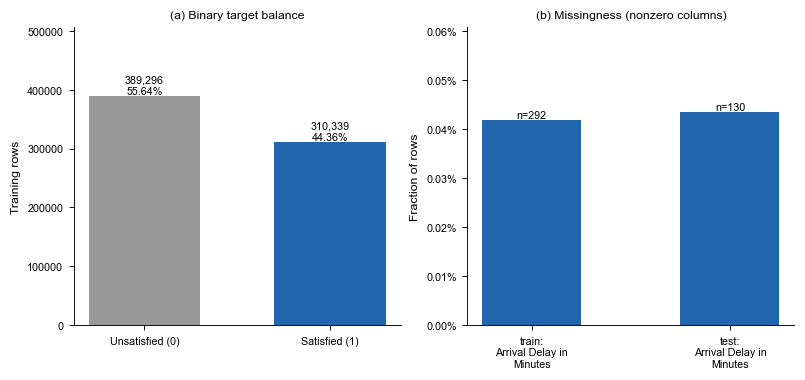

,dataset,feature,dtype,rows,missing,unique,missing_fraction
0,train,id,int64,699635,0,699635,0.000000
1,train,Age,int64,699635,0,75,0.000000
2,train,Flight Distance,int64,699635,0,3474,0.000000
3,train,Inflight wifi service,int64,699635,0,6,0.000000
4,train,Departure/Arrival time convenient,int64,699635,0,6,0.000000
5,train,Ease of Online booking,int64,699635,0,6,0.000000
6,train,Gate location,int64,699635,0,6,0.000000
7,train,Food and drink,int64,699635,0,6,0.000000
8,train,Online boarding,int64,699635,0,6,0.000000
9,train,Seat comfort,int64,699635,0,6,0.000000


In [4]:
display(eda['figures'][0])
display(eda['profile'])

## 2. 连续特征：非线性与阈值

连续特征默认按 20 个分位数分箱，重复分位点合并，每点放在该箱的**实际特征中位数**上。延误零值单列，非零部分分箱；延误横轴使用 symlog（0–1 为线性、其余为对数压缩），不把缺失点接入趋势线。箱内最小值、最大值、中位数、n 均保存在源数据中。

- **Age**：分箱满意率随年龄先升后降，最高年龄箱 `(60, 85]` 约 14.2%，而部分 40–60 岁分箱约 59%–62%。这是非单调线索，不能只放一个线性年龄系数。边界来自探索性分箱，不是已验证切点。
- **Flight Distance**：约 1,200 以上的分箱满意率开始明显升高，之后趋高；需要考虑非线性，并在后续检查是否与舱位、出行目的混杂。
- **Arrival Delay**：0 占绝大多数；6 分钟附近分箱出现满意率下降，不能把分箱边界当成真实机制。缺失组只有 292 条，区间明显较宽。

分箱汇总会隐藏箱内变化，因此这些图用于提出候选关系；正式建模时再比较分箱数、样条或树模型。

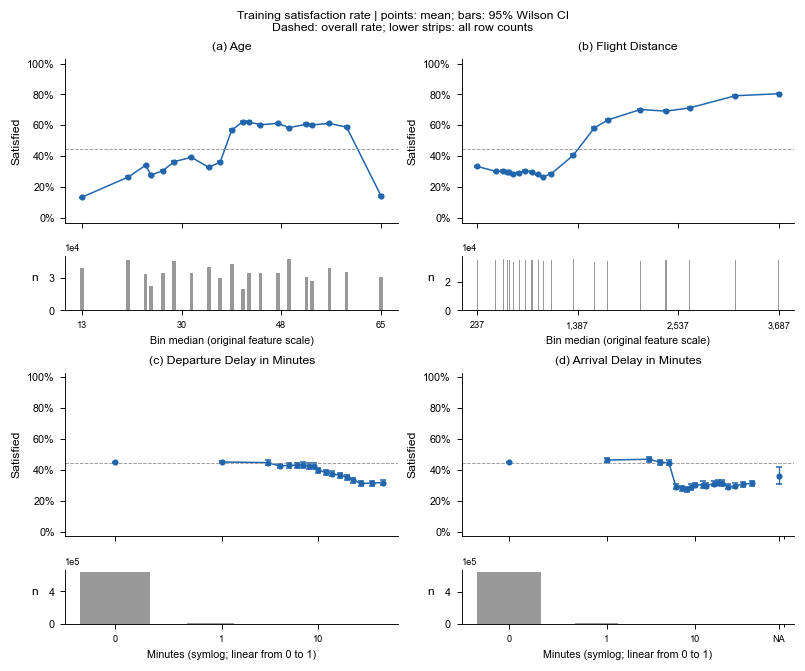

,feature,kind,group,n,positive,rate,x,x_min,x_max,low,high
0,Age,continuous,"(6.999, 17.0]",38932,5262,0.1352,13.0,7,17,0.1318,0.1386
1,Age,continuous,"(17.0, 22.0]",46286,12261,0.2649,21.0,18,22,0.2609,0.2689
2,Age,continuous,"(22.0, 24.0]",33769,11496,0.3404,24.0,23,24,0.3354,0.3455
3,Age,continuous,"(24.0, 25.0]",22387,6230,0.2783,25.0,25,25,0.2725,0.2842
4,Age,continuous,"(25.0, 27.0]",34753,10617,0.3055,27.0,26,27,0.3007,0.3104
5,Age,continuous,"(27.0, 30.0]",45155,16468,0.3647,29.0,28,30,0.3603,0.3692
6,Age,continuous,"(30.0, 33.0]",33914,13311,0.3925,32.0,31,33,0.3873,0.3977
7,Age,continuous,"(33.0, 36.0]",39874,13059,0.3275,35.0,34,36,0.3229,0.3321
8,Age,continuous,"(36.0, 38.0]",29942,10828,0.3616,37.0,37,38,0.3562,0.3671
9,Age,continuous,"(38.0, 40.0]",42199,24043,0.5698,39.0,39,40,0.5650,0.5745


In [5]:
display(eda['figures'][1])
display(eda['rates']['Age'].round(4))

## 3. 服务评分：保留每个原始等级（包括 0）

评分连接线只用于引导阅读，不能解释为相邻等级间已拟合的函数。

- **Online boarding**：评分 1–3 的满意率约 8.5%–12.8%，评分 4、5 分别约 64.2%、87.5%；而评分 0 约 62.0%，存在明显跳变和特殊零值。
- **Inflight wifi service**：0 分约 88.7%，1 分约 39.1%，2–3 分约 27%，5 分约 95.0%。关系强但非单调，不应给它加简单单调约束；0 是否有特殊含义尚未由数据字典确认。
- **Gate location**：Pearson r 仅约 0.023，但评分 3 的满意率约 33.7%，评分 5 约 62.5%。只按线性相关筛选会漏掉这类 U 形关系。

下一步可以比较评分作为数值与类别编码的效果，特殊零值单独标记；这里不预先把零值改成缺失。

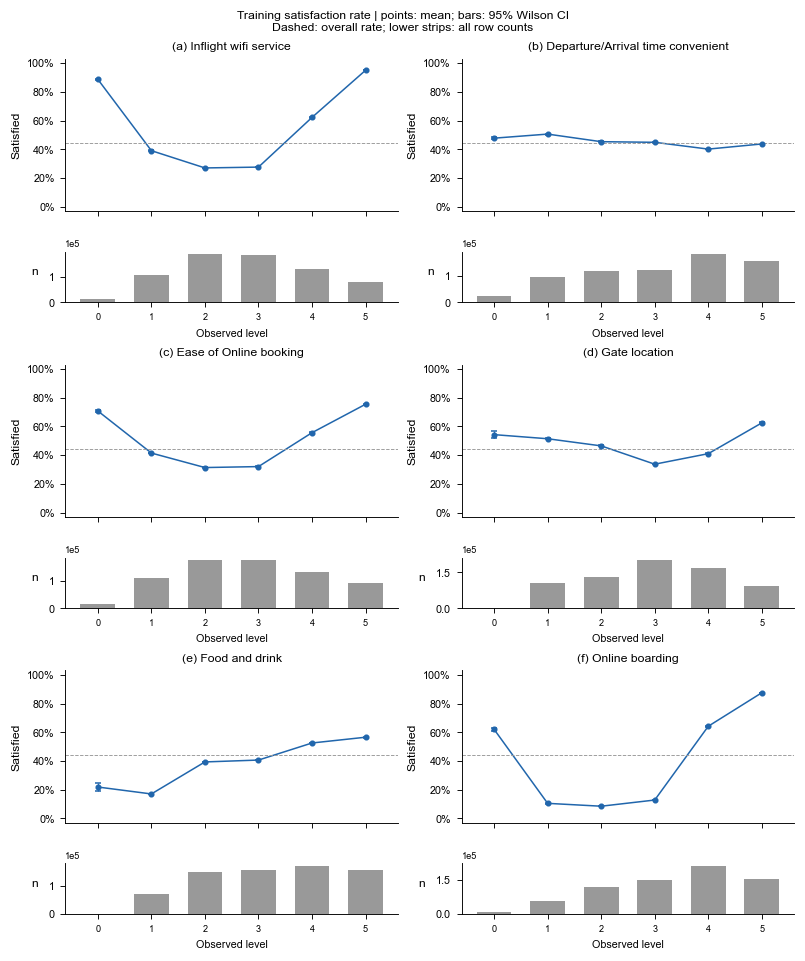

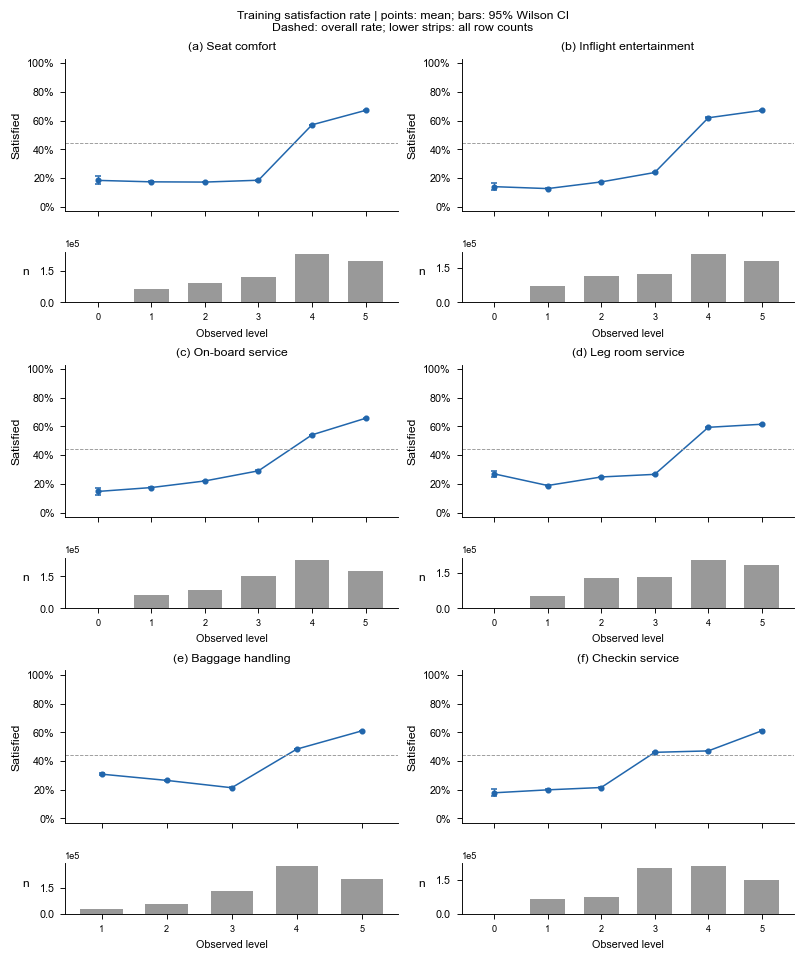

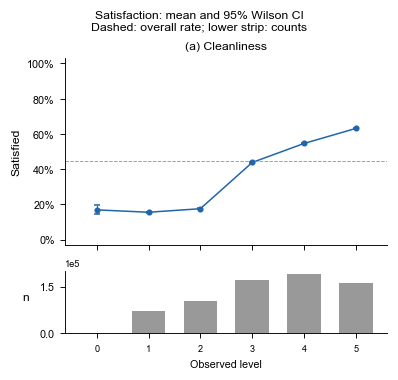

In [6]:
for fig in eda['figures'][2:5]:
    display(fig)

## 4. 类别特征

- **Class**：Business 约 72.5%，Eco 约 16.8%，Eco Plus 约 24.2%。
- **Type of Travel**：Business travel 约 58.4%，Personal Travel 约 9.7%。
- **Customer Type**：忠诚客户组较高；**Gender** 两组只差约 1.1 个百分点，单变量信号较弱。

类别顺序仅用于排版，不给文字类别附加数值大小含义。上述差异未控制其他变量。

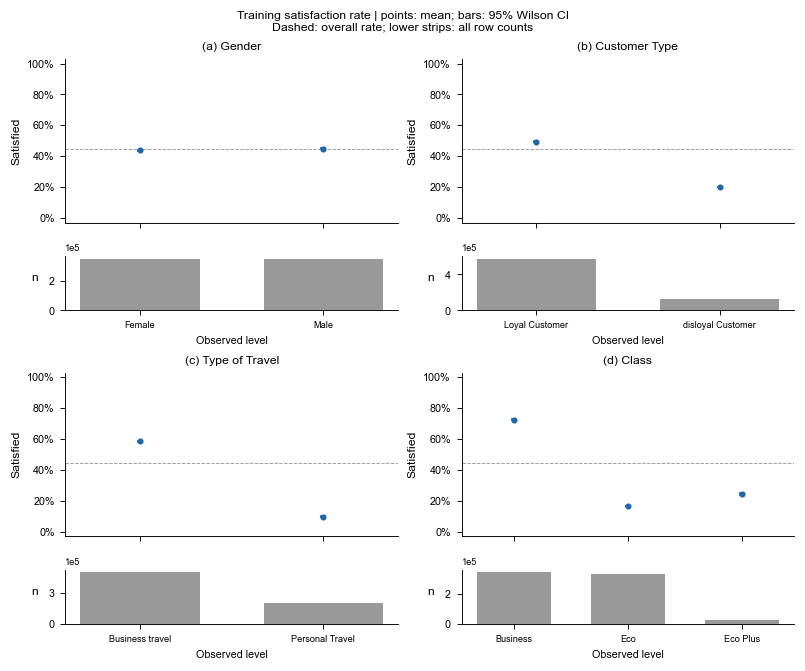

In [7]:
display(eda['figures'][5])

## 5. 哪些特征优先关注？

下面排序使用描述性指标：`Σ(n_g/N) × (p_g − p)² / [p(1−p)]`，即分组满意率的组间方差占二元标签方差的比例（grouped eta-squared）。连续特征使用前述分箱，评分和类别使用原始等级，缺失组也参与。

它用于定位单变量关联，**不是模型重要性、因果效果或验证集分数**。分箱数量、类别数量会影响数值；该指标有样本内偏差，不同特征间只作粗略比较。`supported_rate_gap` 只比较 n≥max(100, 训练集0.1%) 的组，防止稀有组主导极差；该过滤仅用于极差摘要，图和方差统计保留所有组。

优先检查 Online boarding、Class、Inflight wifi service、Inflight entertainment、Type of Travel。Gender 与两项延误的边际信号较弱，但这不能排除交互作用，不能仅凭此图删特征。Pearson / Spearman 也一并提供，类别变量不强行编码求相关。

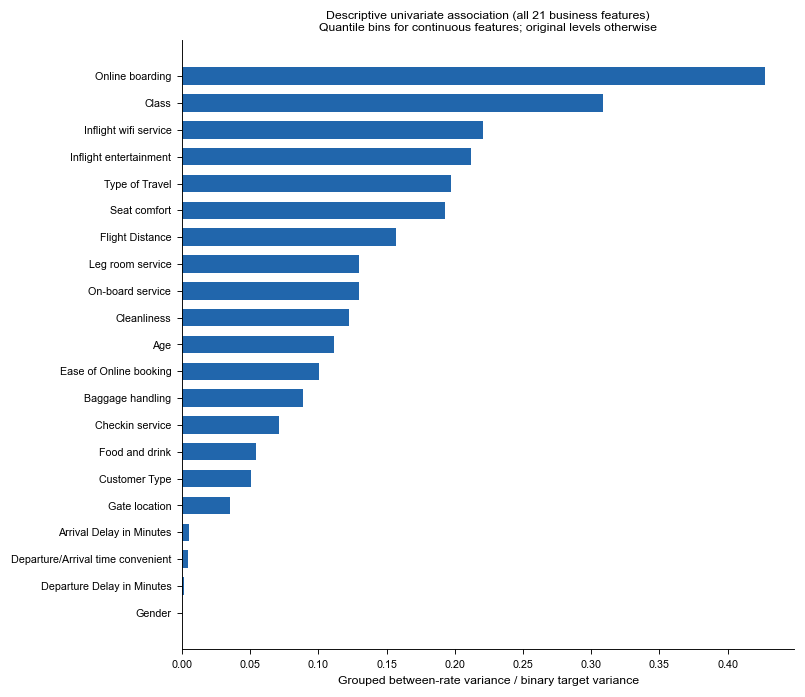

,feature,grouped_eta_squared,supported_rate_gap,pearson,spearman,groups,minimum_group_n
0,Online boarding,0.4276,0.7898,0.5596,0.6020,6,9147
1,Class,0.3088,0.5578,NaN,NaN,3,30019
2,Inflight wifi service,0.2207,0.6799,0.2913,0.2870,6,13102
3,Inflight entertainment,0.2115,0.5444,0.4308,0.4330,6,1020
4,Type of Travel,0.1975,0.4871,NaN,NaN,2,202194
5,Seat comfort,0.1931,0.4991,0.4015,0.4130,6,838
6,Flight Distance,0.1565,0.5379,0.3700,0.3366,20,33480
7,Leg room service,0.1299,0.4264,0.3301,0.3324,6,1693
8,On-board service,0.1297,0.5093,0.3466,0.3541,6,801
9,Cleanliness,0.1227,0.4756,0.3389,0.3347,6,945


In [8]:
display(eda['figures'][6])
display(eda['associations'].round(4))

## 6. 冗余关系与 ID 诊断

Spearman 热图对每一对数值特征使用所有可用的成对观测，label 作为 0/1；ID 和文字类别不进入矩阵。到达延误相关的配对样本数为 699,343，其余通常为 699,635。完整配对计数见 `source_data/correlation_pair_counts.csv`。

在线预订便利度与 Wi-Fi 评分相关约 0.77；座椅舒适度、娱乐、清洁度之间相关约 0.72–0.73。它们可能有冗余，但不能仅凭相关就删除。

ID 按 20 个等宽区间单独检查标签比例是否有顺序漂移；它不计入业务特征排序。此诊断不能证明随机划分足够，也不能证明 ID 有可迁移的预测价值。

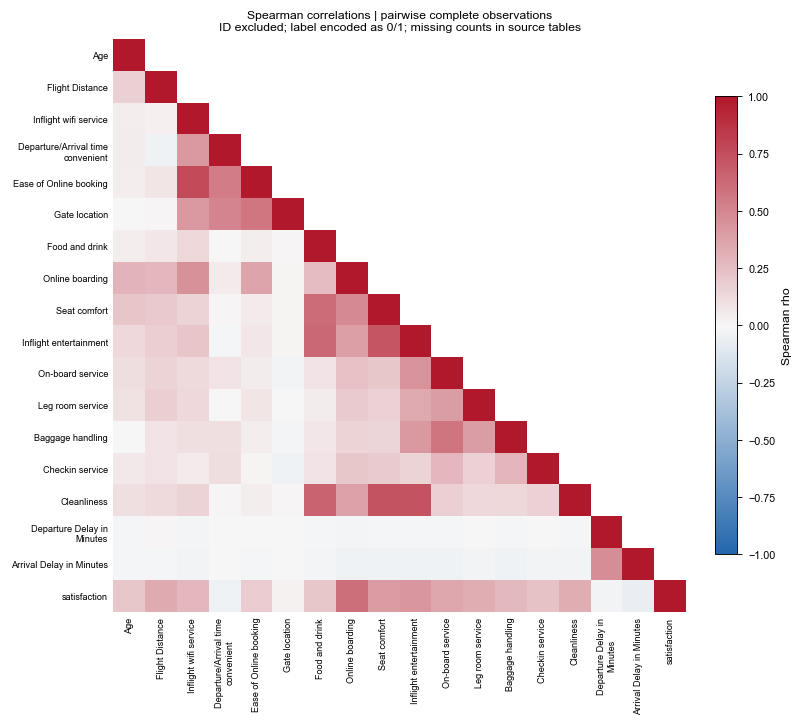

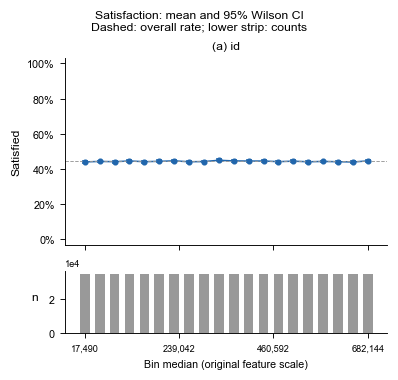

In [9]:
display(eda['figures'][7])
display(eda['figures'][8])

## 统计说明、复现与后续建模

- **n 定义**：一条 CSV 记录为一个观测；没有将其认定为独立旅客或独立重复实验。
- **中心和区间**：组内二元均值＝满意率；误差线为逐点 95% Wilson 二项比例区间，不是 SD/SEM，也不是同时置信区间。这里把记录视作独立 Bernoulli 观测，合成数据的依赖结构可能使该假设失效。
- **检验**：未做假设检验或多重比较校正；不依据 p 值筛选特征。窄区间不代表关系在真实总体或测试集一定成立。
- **数据追溯**：`image/source_data/feature_rates.csv` 包含每个特征的每个箱/等级、计数、正类数量、均值和区间；原始来源为 `train.csv` 对应特征列及 `satisfaction`。`data_profile.csv` 另含 test.csv；其余图有同名意义的汇总表。
- **ML 说明**：本节无模型、无训练/验证划分、无 folds/seeds，无泛化性能估计；后续应在独立验证集比较 ROC-AUC。全训练集满意率（约 44.36%）仅是图中的描述性参考线。
- **建议**：先比较逻辑回归基线与能表达非线性的树模型；重点检查评分零值和等级跳变、年龄非单调、舱位×旅行目的等交互。特征选择、编码和切点必须在训练折内拟合，再用验证集检验；不要将本节全训练集分组满意率直接作为验证集的目标编码。

复现：使用项目指定 Python 环境，从头执行本 notebook；或将项目的 `code/` 加入 `sys.path` 后调用 `run_eda(train, test, output='image')`。全部绘图函数在 `code/plot/airline_eda.py`，具体 QA 与方法记录见 `code/plot/README.md`。